# 4. Does segmentation increase revenue?

**Demand.** A consumer buys a bag if its predicted rating is at least 3 (as in the course). If several bags are offered, they buy the one with the highest predicted rating, if it is at least 3. Predicted ratings come from HB partworths. There are 384 possible bags.

**Strategies.**
- *mass market*: one bag for everyone
- *targeted*: K segments, a bag for each segment, and each consumer can only buy the bag for their segment (the firm can separate segments, e.g. by channel)
- *segment products, open*: the same K segment bags, but everyone can buy any of them
- *optimal line*: K bags chosen jointly for consumers who pick their favourite (no segmentation step)
- *oracle*: every consumer gets the most expensive bag they would still buy (upper bound)

Segments come from latent class (LC) or k-means on HB partworths (part 3).

In [2]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_data, encode, LEVELS, ATTRS
from models import hb
from segments import latent_class
from optimize import profile_matrix, single_revenue, best_single, best_line, line_revenue, targeted_revenue, oracle_revenue
from experiment import repeated_cv

design, online, offline = load_data()
X = encode(design)
B = hb(online, X, seed=0)["B"].mean(0)
P, Zp, p = profile_matrix()
U = B @ Zp.T
n = len(online)

def describe(j):
    return ", ".join(f"{a}={LEVELS[a][P.iloc[j][a] - 1]}" for a in ATTRS)



## In-sample: what the course project did

Products are chosen and evaluated on the same 122 respondents. Revenue is per respondent.

In [3]:
rows = [{"strategy": "mass market", "K": 1, "revenue": single_revenue(U, p).max() / n}]
for K in [2, 3, 4]:
    labels = latent_class(online, X, K)["labels"]
    seg = [best_single(U[labels == k], p) for k in range(K)]
    line = best_line(U, p, K)
    rows.append({"strategy": "targeted (LC)", "K": K, "revenue": targeted_revenue(U, p, labels, seg) / n})
    rows.append({"strategy": "segment products, open (LC)", "K": K, "revenue": line_revenue(U, p, seg) / n})
    rows.append({"strategy": "optimal line", "K": K, "revenue": line_revenue(U, p, line) / n})
rows.append({"strategy": "oracle", "K": n, "revenue": oracle_revenue(U, p) / n})
insample = pd.DataFrame(rows)
insample["gain vs mass market, %"] = 100 * (insample["revenue"] / insample["revenue"].iloc[0] - 1)
insample.round(1)

,strategy,K,revenue,"gain vs mass market, %"
0,mass market,1,135.7,0.0
1,targeted (LC),2,135.7,0.0
2,"segment products, open (LC)",2,133.3,-1.8
3,optimal line,2,142.3,4.8
4,targeted (LC),3,139.3,2.7
5,"segment products, open (LC)",3,139.2,2.5
6,optimal line,3,147.5,8.7
7,targeted (LC),4,141.6,4.3
8,"segment products, open (LC)",4,139.5,2.8
9,optimal line,4,150.3,10.7


In sample every strategy with more than one product looks better than the mass market. But here the same data are used to choose the products and to evaluate them, so these gains are optimistic.

## Out of sample

Repeated 2-fold cross-validation over respondents (10 repetitions, 20 folds). On one half the firm estimates HB, finds segments and chooses products. Revenue is then computed on the other half, using those respondents' partworths from the full-sample HB. Test respondents are assigned to segments from their own ratings.

*Realized* = revenue on the test half from products chosen on the train half. *Potential* = revenue if the firm made the same choices using the test respondents' own partworths, i.e. as if it knew their preferences. Gains are relative to the mass market in the same fold.

In [4]:
cv = pd.DataFrame(repeated_cv(online, X, B, Ks=[1, 2, 3, 4, 5], n_reps=10))
mass = cv[cv["strategy"] == "mass market"].set_index("fold")[["realized", "potential"]]
cv = cv.join(mass, on="fold", rsuffix="_mass")
cv["realized gain, %"] = 100 * (cv["realized"] / cv["realized_mass"] - 1)
cv["potential gain, %"] = 100 * (cv["potential"] / cv["potential_mass"] - 1)

res = (cv[cv["strategy"] != "oracle"].groupby(["strategy", "method", "K"])[["realized gain, %", "potential gain, %"]]
       .agg(["mean", "sem"]).round(1))
res

realized gain, %      potential gain, %     
                                             mean  sem              mean  sem
strategy               method  K                                             
mass market            -       1              0.0  0.0               0.0  0.0
optimal line           -       2              2.4  1.1               6.4  0.5
                               3              4.1  1.1              10.9  0.7
                               4              6.6  1.3              13.5  0.9
                               5              7.1  1.4              15.2  1.0
segment products, open LC      2              0.6  2.0               0.4  0.9
                               3              1.1  1.9               1.7  1.4
                               4              1.9  2.1               2.4  1.4
                               5              1.7  2.2               2.5  1.7
                       k-means 2              2.4  1.7               1.7  0.6
                               3             -0.2  2.1               0.8  1.3
                               4              2.8  2.0               4.1  1.0
                               5              1.5  2.1              -0.4  1.8
targeted               LC      2             -2.0  1.6               1.0  0.3
                               3             -3.6  1.5               4.6  0.6
                               4             -2.8  1.6               6.9  0.8
                               5             -3.8  1.9               8.7  1.0
                       k-means 2             -0.5  1.6               1.9  0.5
                               3              0.6  2.1               5.4  0.7
                               4             -0.9  2.3               7.0  0.7
                               5              1.0  1.7              10.0  0.9

In [6]:
print("mass market revenue per respondent: realized %.1f, potential %.1f" % (mass["realized"].mean(), mass["potential"].mean()))
oracle = cv[cv["strategy"] == "oracle"]
print("oracle gain over potential mass market: %.1f%%" % (100 * (oracle["realized"] / oracle["potential_mass"] - 1)).mean())

mass market revenue per respondent: realized 131.4, potential 136.8
oracle gain over potential mass market: 26.3%


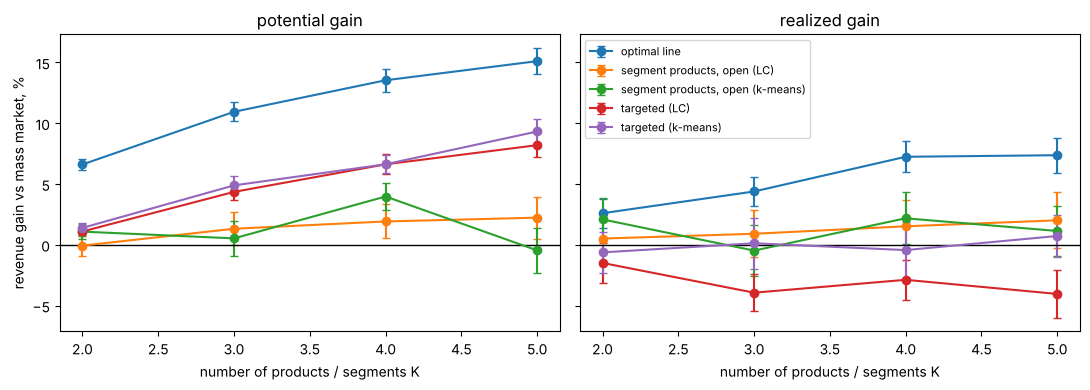

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, col in zip(ax, ["potential gain, %", "realized gain, %"]):
    for (s, m), g in cv[cv["K"] > 1].groupby(["strategy", "method"]):
        if s == "oracle":
            continue
        t = g.groupby("K")[col].agg(["mean", "sem"])
        a.errorbar(t.index, t["mean"], yerr=t["sem"], marker="o", capsize=3, label=f"{s} ({m})" if m != "-" else s)
    a.axhline(0, color="k", lw=1)
    a.set_xlabel("number of products / segments K")
    a.set_title(col.replace(", %", ""))
ax[0].set_ylabel("revenue gain vs mass market, %")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Standard errors are computed across the 20 folds. The folds overlap, so they understate the uncertainty somewhat.

Main results:
- **Targeting segments does not pay out of sample.** With known preferences, targeted segment products would raise revenue by 1-9%. With estimated segments, the realized gain is around zero for k-means and negative for LC (-1.5% to -4%). Segment products for a new half of the sample are chosen from 10-30 people per segment, and many new consumers are assigned to the wrong segment (segments are unstable, part 3), so the potential gain is lost.
- **Offering the segment products to everyone** gives at most +2%, not significantly different from zero.
- **An optimal product line pays.** Choosing K bags jointly on individual partworths gives +2.6% (2 bags) to +7% (4-5 bags) out of sample, about half of its potential gain.
- **Even the mass-market bag loses about 4%** when chosen on half of the sample instead of the test respondents themselves.

So for this data the answer depends on how segmentation is used: grouping consumers first and designing a product per group does not increase revenue, while designing a product line directly on individual-level preferences does. The next part uses simulations to see when segment targeting would start to pay (more respondents, more distinct segments).

## Products

Mass market bag and the optimal line of 3 bags on the full sample.

In [7]:
print("mass market:", describe(best_single(U, p)))
for j in best_line(U, p, 3):
    print("line:", describe(j))

mass market: exterior=black, size=large, price=180, strap_pad=yes, pocket=yes, interior=laptop
line: exterior=black, size=small, price=180, strap_pad=no, pocket=no, interior=laptop
line: exterior=black, size=large, price=180, strap_pad=yes, pocket=yes, interior=laptop
line: exterior=blue, size=small, price=140, strap_pad=yes, pocket=yes, interior=no_dividers


The mass-market bag is the full-featured black large bag at the highest price. The 3-bag line keeps it and adds two variants: a small black bag with a laptop compartment at $180 for those who don't need the extra features, and a blue small bag at $140 for price-sensitive consumers.